#Entrega 1
##**Paper:** Prevalence and Predictors of Pre-Diabetes and Diabetes among Adults 18 Years or Older in Florida: A Multinomial Logistic Modeling Approach

###Integrantes:
* Jean Paul Rojas Rojas
* Mariana Uribe Vanegas


##Dataset
Base de datos SANUT 2025


In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
import os
import pandas as pd

path_df = '/content/drive/MyDrive/Base mx/Adultos 20 años/base_diabetes_ensanut2025.csv'

df = pd.read_csv(path_df)
print(f"Base de datos cargada correctamente de forma segura. Dimensiones: {df.shape}")

Base de datos cargada correctamente de forma segura. Dimensiones: (8475, 20)


In [4]:
import numpy as np
import pandas as pd

# 1. CARACTERIZACIÓN INICIAL Y AUDITORÍA DE CALIDAD COMPLETA

# Verificación y limpieza de posibles infinitos
print("AUDITORÍA DE VALORES INFINITOS Y VALORES FUERA DE RANGO ")
for col in df.select_dtypes(include=[np.number]).columns:
    inf_count = np.isinf(df[col]).sum()
    if inf_count > 0:
        print(f"   - ¡Alerta! Variable {col} tiene {inf_count} valores infinitos. Se reemplazarán por NaN.")
        df[col] = df[col].replace([np.inf, -np.inf], np.nan)

# Validación estricta de la variable objetivo (DIABETES)
valores_target = df['DIABETES'].unique()
print(f"   - Valores únicos en variable objetivo (DIABETES): {valores_target}")
assert set(valores_target).issubset({0, 1}), "Error crítico: La variable objetivo contiene valores distintos de 0 y 1."

# Validación de variables binarias
cols_bin = ['HIPERTENSION', 'COLESTEROL_ALTO', 'TRIGLICERIDOS_ALTOS',
            'ENF_RENAL', 'ENF_CARDIOVASCULAR', 'DIF_CAMINAR',
            'SIN_SEGURO_SALUD', 'TRABAJA']
print("\n VALIDACIÓN DE VARIABLES BINARIAS (0 o 1) ")
for col in cols_bin:
    valores_unicos = df[col].dropna().unique()
    invalido = [v for v in valores_unicos if v not in [0, 1]]
    print(f"   - {col:25s}: Valores detectados {valores_unicos} | Inválidos: {len(invalido)}")
    assert len(invalido) == 0, f"Error: La variable {col} contiene valores no binarios: {invalido}"

# Validación de categorías inesperadas
cols_cat = ['SEXO', 'TABAQUISMO', 'CONSUMO_ALCOHOL', 'NIVEL_EDUCATIVO', 'ESTRATO_URBANO']
print("\n DETALLE DE CATEGORÍAS EN VARIABLES CATEGÓRICAS ")
for col in cols_cat:
    print(f"   - {col}: {df[col].unique().tolist()}")

# Dimensiones y verificación de unicidad
print("\n DIMENSIONES Y UNICIDAD DE OBSERVACIONES ")
print(f"   - Total de registros (filas):    {df.shape[0]:,}")
print(f"   - Total de columnas:             {df.shape[1]}")
print(f"   - Filas duplicadas exactas:      {df.duplicated().sum()}")
print(f"   - Individuos duplicados (llave): {df.duplicated(subset=['FOLIO_I', 'FOLIO_INT']).sum()}")

# Distribución de la variable objetivo (DIABETES)
print("\n DISTRIBUCIÓN DE VARIABLE OBJETIVO (DIABETES) ")
conteo_target = df['DIABETES'].value_counts()
prop_target = df['DIABETES'].value_counts(normalize=True) * 100
resumen_target = pd.DataFrame({
    'Clase': ['0 - Sin diabetes', '1 - Con diabetes'],
    'Frecuencia (n)': [conteo_target.get(0, 0), conteo_target.get(1, 0)],
    'Porcentaje (%)': [round(prop_target.get(0, 0), 2), round(prop_target.get(1, 0), 2)]
})
print(resumen_target.to_string(index=False))

AUDITORÍA DE VALORES INFINITOS Y VALORES FUERA DE RANGO 
   - Valores únicos en variable objetivo (DIABETES): [0 1]

 VALIDACIÓN DE VARIABLES BINARIAS (0 o 1) 
   - HIPERTENSION             : Valores detectados [0 1] | Inválidos: 0
   - COLESTEROL_ALTO          : Valores detectados [0 1] | Inválidos: 0
   - TRIGLICERIDOS_ALTOS      : Valores detectados [0 1] | Inválidos: 0
   - ENF_RENAL                : Valores detectados [0 1] | Inválidos: 0
   - ENF_CARDIOVASCULAR       : Valores detectados [0 1] | Inválidos: 0
   - DIF_CAMINAR              : Valores detectados [0 1] | Inválidos: 0
   - SIN_SEGURO_SALUD         : Valores detectados [1 0] | Inválidos: 0
   - TRABAJA                  : Valores detectados [0 1] | Inválidos: 0

 DETALLE DE CATEGORÍAS EN VARIABLES CATEGÓRICAS 
   - SEXO: ['Mujer', 'Hombre']
   - TABAQUISMO: ['Nunca_fumo', 'Fumador_actual', 'Exfumador', 'No_responde']
   - CONSUMO_ALCOHOL: ['Ocasional', 'No_consume', 'Frecuente_semanal', 'No_responde']
   - NIVEL_EDUCATIV

In [5]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    recall_score,
    precision_score,
    f1_score,
    roc_auc_score,
    make_scorer
)

# 2. PARTICIÓN SIN FUGA Y MODELO DE LÍNEA BASE

# 1. Separación de predictores (X) y variable objetivo (y)
# Se excluyen los identificadores FOLIO_I y FOLIO_INT para evitar memorización
X = df.drop(columns=['FOLIO_I', 'FOLIO_INT', 'DIABETES'])
y = df['DIABETES']

# 2. Partición estratificada 80% entrenamiento / 20% prueba con semilla fija
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print("1. PARTICIÓN ESTRATIFICADA (80 / 20)")
print(f"   - Entrenamiento (X_train): {X_train.shape[0]:,} filas ({len(X_train)/len(X)*100:.1f}%) | Prevalencia diabetes: {y_train.mean()*100:.2f}%")
print(f"   - Prueba (X_test):         {X_test.shape[0]:,} filas ({len(X_test)/len(X)*100:.1f}%) | Prevalencia diabetes: {y_test.mean()*100:.2f}%")

# Verificación explícita de cero solapamiento de personas entre Train y Test
ids_train = set(df.loc[X_train.index, 'FOLIO_INT'])
ids_test = set(df.loc[X_test.index, 'FOLIO_INT'])
print(f"   - Individuos compartidos entre Train y Test: {len(ids_train.intersection(ids_test))}")

# 3. Preprocesador integrado (se ajusta únicamente con datos de entrenamiento)
cols_num = ['EDAD', 'IMC', 'PAS_MEDIA', 'PAD_MEDIA']
cols_cat = ['SEXO', 'TABAQUISMO', 'CONSUMO_ALCOHOL', 'NIVEL_EDUCATIVO', 'ESTRATO_URBANO']
cols_bin = ['HIPERTENSION', 'COLESTEROL_ALTO', 'TRIGLICERIDOS_ALTOS',
            'ENF_RENAL', 'ENF_CARDIOVASCULAR', 'DIF_CAMINAR',
            'SIN_SEGURO_SALUD', 'TRABAJA']

preprocesador = ColumnTransformer(
    transformers=[
        ('num', Pipeline([
            ('imputer', SimpleImputer(strategy='median')),
            ('scaler', StandardScaler())
        ]), cols_num),
        ('cat', OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False), cols_cat),
        ('bin', 'passthrough', cols_bin)
    ]
)

# 4. Pipeline reproducible del Modelo de Línea Base (clasificador de clase mayoritaria)
pipeline_baseline = Pipeline(steps=[
    ('preprocesamiento', preprocesador),
    ('clasificador', DummyClassifier(strategy='most_frequent', random_state=42))
])

# 5. Validación cruzada estratificada (5 folds) en entrenamiento
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = {
    'accuracy': 'accuracy',
    'recall': make_scorer(recall_score, zero_division=0),
    'precision': make_scorer(precision_score, zero_division=0),
    'f1': make_scorer(f1_score, zero_division=0),
    'roc_auc': 'roc_auc'
}

metricas_cv = cross_validate(pipeline_baseline, X_train, y_train, cv=cv, scoring=scoring)

print("\n2. VALIDACIÓN CRUZADA ESTRATIFICADA (5-FOLDS EN TRAIN) - LÍNEA BASE")
for metrica in scoring:
    valores = metricas_cv[f'test_{metrica}']
    print(f"   - {metrica.upper():10s}: {valores.mean():.4f} ± {valores.std():.4f}")

# 6. Ajuste final en X_train y evaluación sobre el conjunto de prueba (X_test)
pipeline_baseline.fit(X_train, y_train)
y_pred_test = pipeline_baseline.predict(X_test)
y_prob_test = pipeline_baseline.predict_proba(X_test)[:, 1]

tn, fp, fn, tp = confusion_matrix(y_test, y_pred_test).ravel()
especificidad = tn / (tn + fp)

print("\n3. EVALUACIÓN EN CONJUNTO DE PRUEBA (TEST 20%) - LÍNEA BASE")
print(f"   - Accuracy (Exactitud):        {accuracy_score(y_test, y_pred_test):.4f}")
print(f"   - Recall (Sensibilidad Y=1):   {recall_score(y_test, y_pred_test, zero_division=0):.4f}")
print(f"   - Especificidad (Y=0):         {especificidad:.4f}")
print(f"   - Precision (Y=1):             {precision_score(y_test, y_pred_test, zero_division=0):.4f}")
print(f"   - F1-Score (Y=1):              {f1_score(y_test, y_pred_test, zero_division=0):.4f}")
print(f"   - ROC-AUC:                     {roc_auc_score(y_test, y_prob_test):.4f}")

print("\n4. MATRIZ DE CONFUSIÓN (TEST)")
cm_df = pd.DataFrame(
    [[tn, fp], [fn, tp]],
    index=['Real: 0 (Sin diabetes)', 'Real: 1 (Con diabetes)'],
    columns=['Pred: 0 (Sin diabetes)', 'Pred: 1 (Con diabetes)']
)
print(cm_df.to_string())
print(f"\nDimensión matriz tras preprocesamiento: {pipeline_baseline.named_steps['preprocesamiento'].transform(X_train).shape[1]} columnas")


1. PARTICIÓN ESTRATIFICADA (80 / 20)
   - Entrenamiento (X_train): 6,780 filas (80.0%) | Prevalencia diabetes: 16.61%
   - Prueba (X_test):         1,695 filas (20.0%) | Prevalencia diabetes: 16.64%
   - Individuos compartidos entre Train y Test: 0

2. VALIDACIÓN CRUZADA ESTRATIFICADA (5-FOLDS EN TRAIN) - LÍNEA BASE
   - ACCURACY  : 0.8339 ± 0.0003
   - RECALL    : 0.0000 ± 0.0000
   - PRECISION : 0.0000 ± 0.0000
   - F1        : 0.0000 ± 0.0000
   - ROC_AUC   : 0.5000 ± 0.0000

3. EVALUACIÓN EN CONJUNTO DE PRUEBA (TEST 20%) - LÍNEA BASE
   - Accuracy (Exactitud):        0.8336
   - Recall (Sensibilidad Y=1):   0.0000
   - Especificidad (Y=0):         1.0000
   - Precision (Y=1):             0.0000
   - F1-Score (Y=1):              0.0000
   - ROC-AUC:                     0.5000

4. MATRIZ DE CONFUSIÓN (TEST)
                        Pred: 0 (Sin diabetes)  Pred: 1 (Con diabetes)
Real: 0 (Sin diabetes)                    1413                       0
Real: 1 (Con diabetes)               

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 3. VISUALIZACIÓN EXPLORATORIA Y TABLAS DE RESPALDO

plt.rcParams['figure.dpi'] = 140
plt.rcParams['savefig.dpi'] = 300
sns.set_theme(style='whitegrid', context='notebook')

paleta = ['#2b5c8f', '#d95f02']  # Azul: Sin diabetes (0) | Naranja: Con diabetes (1)


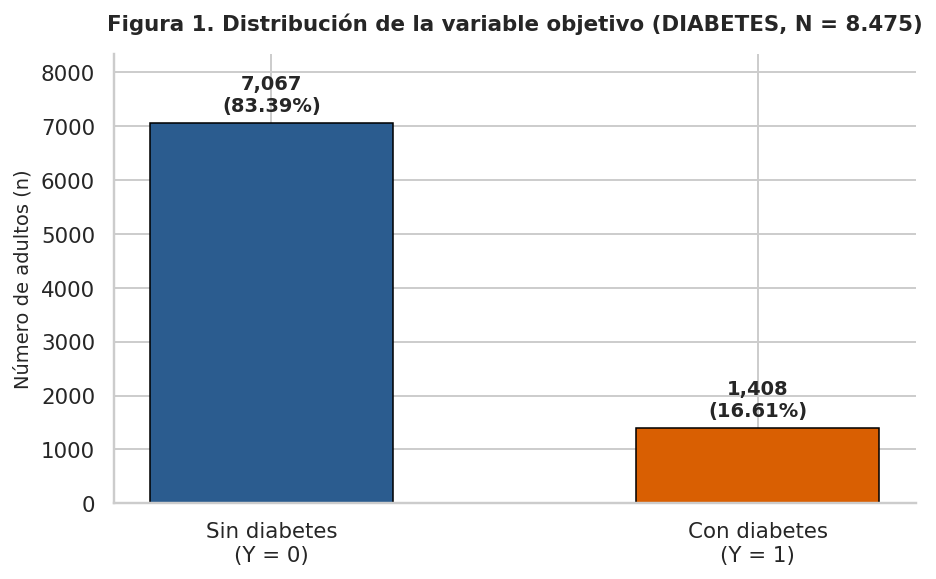

In [7]:
# FIGURA 1: DISTRIBUCIÓN DE LA VARIABLE OBJETIVO (DIABETES)
fig, ax = plt.subplots(figsize=(6.8, 4.3))
conteos = df['DIABETES'].value_counts().sort_index()
porcentajes = df['DIABETES'].value_counts(normalize=True).sort_index() * 100
etiquetas = ['Sin diabetes\n(Y = 0)', 'Con diabetes\n(Y = 1)']

bars = ax.bar(etiquetas, conteos.values, color=paleta, width=0.50, edgecolor='black', linewidth=0.8)
ax.set_title('Figura 1. Distribución de la variable objetivo (DIABETES, N = 8.475)', fontsize=11, fontweight='bold', pad=12)
ax.set_ylabel('Número de adultos (n)', fontsize=10)
ax.set_ylim(0, conteos.max() * 1.18)

for bar, n_val, pct_val in zip(bars, conteos.values, porcentajes.values):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 140,
        f'{n_val:,}\n({pct_val:.2f}%)',
        ha='center', va='bottom', fontsize=10, fontweight='bold'
    )

sns.despine(top=True, right=True)
plt.tight_layout()
plt.savefig('figura1_distribucion_diabetes.png', bbox_inches='tight')
plt.show()

/tmp/ipykernel_7979/3620196573.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_7979/3620196573.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_7979/3620196573.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


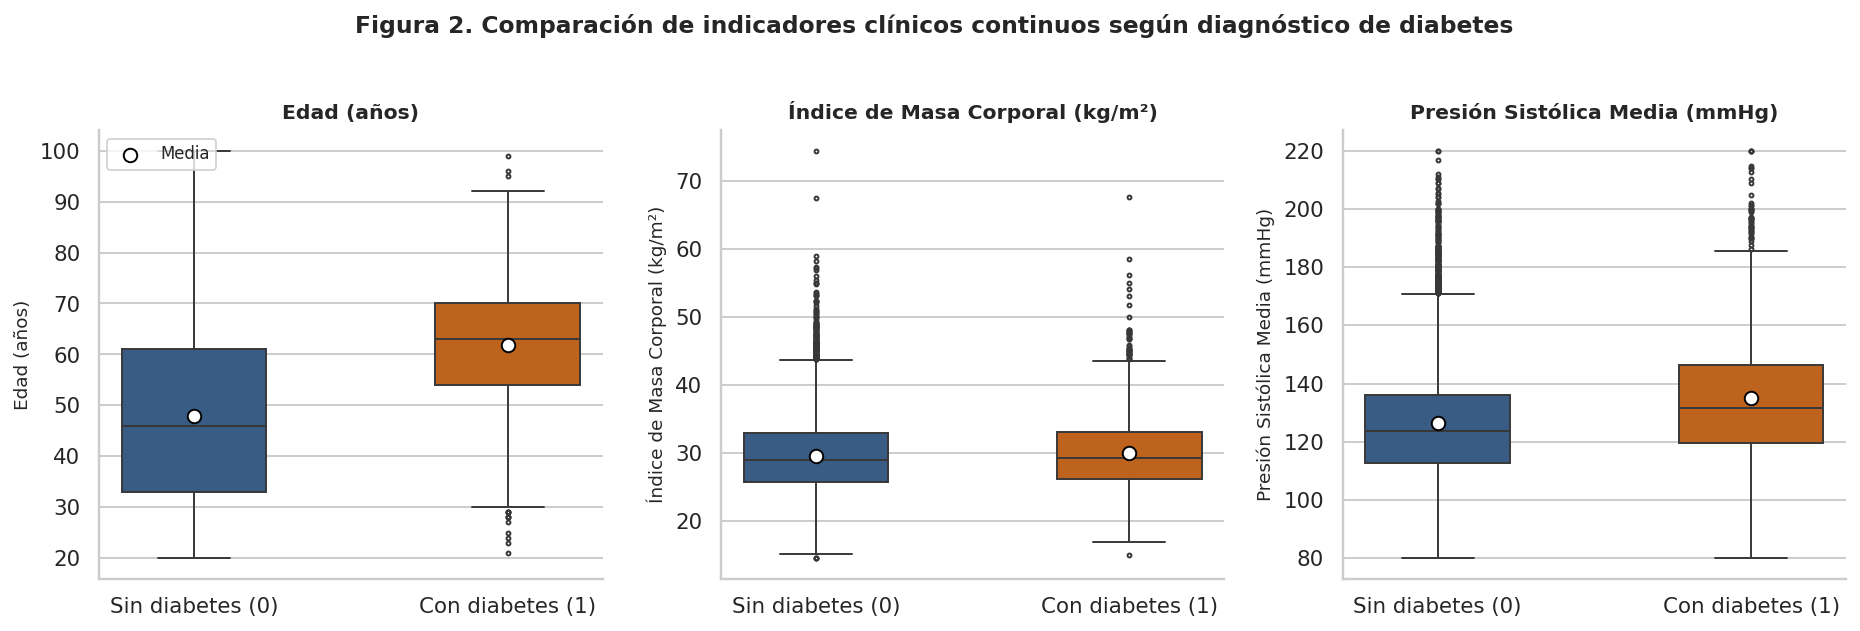

In [8]:
# FIGURA 2: INDICADORES CLÍNICOS CONTINUOS SEGÚN DIAGNÓSTICO DE DIABETES
fig, axes = plt.subplots(1, 3, figsize=(13.5, 4.4))
vars_num_plot = [
    ('EDAD', 'Edad (años)'),
    ('IMC', 'Índice de Masa Corporal (kg/m²)'),
    ('PAS_MEDIA', 'Presión Sistólica Media (mmHg)')
]

df_plot = df.copy()
df_plot['Grupo'] = df_plot['DIABETES'].map({0: 'Sin diabetes (0)', 1: 'Con diabetes (1)'})
orden_grupos = ['Sin diabetes (0)', 'Con diabetes (1)']

for ax, (col, titulo) in zip(axes, vars_num_plot):
    sns.boxplot(
        data=df_plot, x='Grupo', y=col, order=orden_grupos,
        palette=paleta, width=0.46, fliersize=2, ax=ax
    )
    medias = df_plot.groupby('DIABETES')[col].mean()
    ax.scatter([0, 1], [medias[0], medias[1]], color='white', edgecolor='black', zorder=5, s=48, label='Media')
    ax.set_title(titulo, fontsize=10.5, fontweight='bold')
    ax.set_xlabel('')
    ax.set_ylabel(titulo, fontsize=9.5)
    sns.despine(ax=ax, top=True, right=True)

axes[0].legend(loc='upper left', frameon=True, fontsize=8.5)
fig.suptitle('Figura 2. Comparación de indicadores clínicos continuos según diagnóstico de diabetes', fontsize=12, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('figura2_indicadores_continuos.png', bbox_inches='tight')
plt.show()


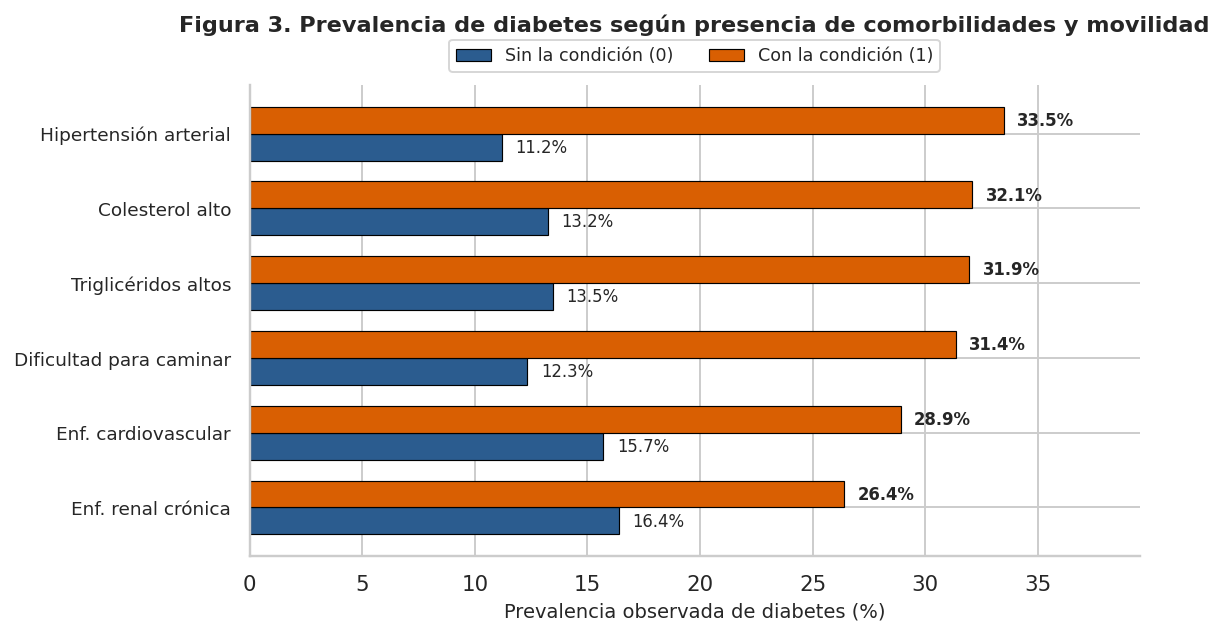


 TABLA DESCRIPTIVA POR GRUPO DE DIABETES
           EDAD                  IMC              PAS_MEDIA                PAD_MEDIA              
           mean    std median   mean   std median      mean    std  median      mean    std median
DIABETES                                                                                          
0         47.84  17.55   46.0  29.64  5.89  29.03    126.27  20.06  123.67     75.29  11.23  74.67
1         61.91  11.91   63.0  30.08  6.00  29.24    134.99  22.52  131.50     74.44  11.42  73.67

 PREVALENCIA DE DIABETES SEGÚN FACTOR CLÍNICO
                 Factor  Con condición (1)  Sin condición (0)  Razón (Con / Sin)
  Hipertensión arterial              33.50              11.21               2.99
        Colesterol alto              32.10              13.25               2.42
    Triglicéridos altos              31.95              13.47               2.37
Dificultad para caminar              31.36              12.33               2.54
    Enf. ca

In [9]:
# FIGURA 3: PREVALENCIA DE DIABETES POR COMORBILIDADES Y MOVILIDAD
factores_bin = [
    ('HIPERTENSION', 'Hipertensión arterial'),
    ('COLESTEROL_ALTO', 'Colesterol alto'),
    ('TRIGLICERIDOS_ALTOS', 'Triglicéridos altos'),
    ('DIF_CAMINAR', 'Dificultad para caminar'),
    ('ENF_CARDIOVASCULAR', 'Enf. cardiovascular'),
    ('ENF_RENAL', 'Enf. renal crónica')
]

filas_prev = []
for col, nombre in factores_bin:
    prev_con = df.loc[df[col] == 1, 'DIABETES'].mean() * 100
    prev_sin = df.loc[df[col] == 0, 'DIABETES'].mean() * 100
    filas_prev.append({'Factor': nombre, 'Con condición (1)': prev_con, 'Sin condición (0)': prev_sin})

df_prev = pd.DataFrame(filas_prev).sort_values('Con condición (1)', ascending=True)

fig, ax = plt.subplots(figsize=(8.4, 4.7))
y_pos = np.arange(len(df_prev))
alto = 0.36

ax.barh(y_pos - alto/2, df_prev['Sin condición (0)'], height=alto, color='#2b5c8f', label='Sin la condición (0)', edgecolor='black', linewidth=0.6)
ax.barh(y_pos + alto/2, df_prev['Con condición (1)'], height=alto, color='#d95f02', label='Con la condición (1)', edgecolor='black', linewidth=0.6)

for i, (v0, v1) in enumerate(zip(df_prev['Sin condición (0)'], df_prev['Con condición (1)'])):
    ax.text(v0 + 0.6, i - alto/2, f'{v0:.1f}%', va='center', fontsize=8.5)
    ax.text(v1 + 0.6, i + alto/2, f'{v1:.1f}%', va='center', fontsize=8.5, fontweight='bold')

ax.set_yticks(y_pos)
ax.set_yticklabels(df_prev['Factor'], fontsize=9.5)
ax.set_xlabel('Prevalencia observada de diabetes (%)', fontsize=10)
ax.set_title('Figura 3. Prevalencia de diabetes según presencia de comorbilidades y movilidad', fontsize=11.5, fontweight='bold', pad=28)
ax.set_xlim(0, df_prev['Con condición (1)'].max() * 1.18)
ax.legend(loc='lower center', bbox_to_anchor=(0.5, 1.01), ncol=2, frameon=True, fontsize=9)
sns.despine(top=True, right=True)
plt.tight_layout()
plt.savefig('figura3_prevalencia_comorbilidades.png', bbox_inches='tight')
plt.show()
print("\n TABLA DESCRIPTIVA POR GRUPO DE DIABETES")
resumen_num = df.groupby('DIABETES')[['EDAD', 'IMC', 'PAS_MEDIA', 'PAD_MEDIA']].agg(['mean', 'std', 'median']).round(2)
print(resumen_num.to_string())

print("\n PREVALENCIA DE DIABETES SEGÚN FACTOR CLÍNICO")
df_prev_tab = df_prev.sort_values('Con condición (1)', ascending=False).copy()
df_prev_tab['Razón (Con / Sin)'] = (df_prev_tab['Con condición (1)'] / df_prev_tab['Sin condición (0)']).round(2)
print(df_prev_tab.round(2).to_string(index=False))

# Entrega 2

##1. Consolidación de los datos


In [10]:
import numpy as np
import pandas as pd

print("1. ESTRUCTURA DEL CONJUNTO DEFINITIVO (ENSANUT 2025)")
print("   - Fuente: Encuesta Nacional de Salud y Nutrición (ENSANUT 2025 - América Latina)")
print(f"   - Dimensiones totales:         {df.shape[0]:,} registros x {df.shape[1]} columnas")
print("   - Identificadores (llave):     FOLIO_I (hogar), FOLIO_INT (individuo)")
print("   - Variable objetivo:           DIABETES (0 = No, 1 = Sí)")
print(f"   - Total predictores:           {df.shape[1] - 3} variables (4 numéricas, 8 binarias, 5 categóricas)")
print(f"   - Filas duplicadas:            {df.duplicated().sum()}")
print(f"   - Individuos duplicados:       {df.duplicated(subset=['FOLIO_I', 'FOLIO_INT']).sum()}")

# 2. Auditoría de completitud (valores faltantes por variable y por fila)
filas_con_nulos = df.isna().any(axis=1).sum()
filas_completas = len(df) - filas_con_nulos
print("\n2. ESTADO DE CALIDAD Y VALORES FALTANTES")
print(f"   - Registros 100% completos:    {filas_completas:,} ({filas_completas/len(df)*100:.2f}%)")
print(f"   - Registros con algún nulo:    {filas_con_nulos:,} ({filas_con_nulos/len(df)*100:.2f}%)")

calidad = pd.DataFrame({
    'Tipo': df.dtypes.astype(str),
    'No_Nulos': df.notna().sum(),
    'Nulos': df.isna().sum(),
    'Pct_Nulos (%)': (df.isna().mean() * 100).round(2),
    'Unicos': df.nunique()
})
print("\nDetalle por columna:")
print(calidad.to_string())

# 3. Análisis de distribución, asimetría y valores atípicos (IQR) en variables numéricas
cols_num = ['EDAD', 'IMC', 'PAS_MEDIA', 'PAD_MEDIA']
print("\n3. DIAGNÓSTICO DE VARIABLES NUMÉRICAS CONTINUAS (RANGOS, ASIMETRÍA Y OUTLIERS IQR)")
stats_num = []
for col in cols_num:
    s = df[col].dropna()
    q1, med, q3 = np.percentile(s, [25, 50, 75])
    iqr = q3 - q1
    lim_inf = q1 - 1.5 * iqr
    lim_sup = q3 + 1.5 * iqr
    n_out = ((s < lim_inf) | (s > lim_sup)).sum()
    stats_num.append({
        'Variable': col,
        'N_valido': len(s),
        'Media': round(s.mean(), 2),
        'DE': round(s.std(), 2),
        'Min': round(s.min(), 2),
        'Q1': round(q1, 2),
        'Mediana': round(med, 2),
        'Q3': round(q3, 2),
        'Max': round(s.max(), 2),
        'Asimetria': round(s.skew(), 2),
        'Outliers_IQR (n)': n_out,
        'Outliers_IQR (%)': round(n_out / len(s) * 100, 2)
    })
print(pd.DataFrame(stats_num).to_string(index=False))

# 4. Verificación de colinealidad entre predictores numéricos y binarios con comprobación de singularidad
cols_bin = ['HIPERTENSION', 'COLESTEROL_ALTO', 'TRIGLICERIDOS_ALTOS',
            'ENF_RENAL', 'ENF_CARDIOVASCULAR', 'DIF_CAMINAR',
            'SIN_SEGURO_SALUD', 'TRABAJA']

variables_analisis = cols_num + cols_bin
df_num_bin = df[variables_analisis].dropna().copy()

# Filtrar variables sin varianza para evitar divisiones entre cero o matriz singular
varianzas = df_num_bin.var()
variables_validas = varianzas[varianzas > 1e-9].index.tolist()

df_num_bin = df_num_bin[variables_validas]
corr_matrix = df_num_bin.corr()

# Verificación segura del rango de la matriz antes de calcular la inversa
rango_matriz = np.linalg.matrix_rank(corr_matrix.values)
n_features = corr_matrix.shape[1]

if rango_matriz < n_features:
    corr_inv = np.linalg.pinv(corr_matrix.values)
else:
    corr_inv = np.linalg.inv(corr_matrix.values)

vif_vals = np.diag(corr_inv)

df_vif = pd.DataFrame({
    'Variable': variables_validas,
    'VIF': np.round(vif_vals, 3),
    'Corr_con_DIABETES': [round(df[c].corr(df['DIABETES']), 3) for c in variables_validas]
}).sort_values('VIF', ascending=False)

print("\n4. DIAGNÓSTICO DE MULTICOLINEALIDAD (VIF) Y ASOCIACIÓN LINEAL CON DIABETES")
print(df_vif.to_string(index=False))

if 'PAS_MEDIA' in variables_validas and 'PAD_MEDIA' in variables_validas:
    print(f"\n   - Correlación más alta entre predictores: PAS_MEDIA vs PAD_MEDIA = {corr_matrix.loc['PAS_MEDIA', 'PAD_MEDIA']:.3f}")
if 'COLESTEROL_ALTO' in variables_validas and 'TRIGLICERIDOS_ALTOS' in variables_validas:
    print(f"   - Correlación COLESTEROL_ALTO vs TRIGLICERIDOS_ALTOS = {corr_matrix.loc['COLESTEROL_ALTO', 'TRIGLICERIDOS_ALTOS']:.3f}")

1. ESTRUCTURA DEL CONJUNTO DEFINITIVO (ENSANUT 2025)
   - Fuente: Encuesta Nacional de Salud y Nutrición (ENSANUT 2025 - América Latina)
   - Dimensiones totales:         8,475 registros x 20 columnas
   - Identificadores (llave):     FOLIO_I (hogar), FOLIO_INT (individuo)
   - Variable objetivo:           DIABETES (0 = No, 1 = Sí)
   - Total predictores:           17 variables (4 numéricas, 8 binarias, 5 categóricas)
   - Filas duplicadas:            0
   - Individuos duplicados:       0

2. ESTADO DE CALIDAD Y VALORES FALTANTES
   - Registros 100% completos:    7,968 (94.02%)
   - Registros con algún nulo:    507 (5.98%)

Detalle por columna:
                        Tipo  No_Nulos  Nulos  Pct_Nulos (%)  Unicos
FOLIO_I               object      8475      0           0.00    6870
FOLIO_INT             object      8475      0           0.00    8475
DIABETES               int64      8475      0           0.00       2
EDAD                   int64      8475      0           0.00      81
SE

#2. Flujo reproducible sin fuga de datos

In [11]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.dummy import DummyClassifier
from sklearn.metrics import make_scorer, recall_score, precision_score, f1_score

cols_id = ['FOLIO_I', 'FOLIO_INT']
target = 'DIABETES'

X = df.drop(columns=cols_id + [target])
y = df[target]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

ids_train = set(df.loc[X_train.index, 'FOLIO_INT'])
ids_test = set(df.loc[X_test.index, 'FOLIO_INT'])

print("1. AUDITORÍA DE PARTICIÓN ESTRATIFICADA (ANTES DEL PREPROCESAMIENTO)")
print(f"   - Conjunto de entrenamiento (X_train): {X_train.shape[0]:,} filas | DIABETES=1: {y_train.sum():,} ({y_train.mean()*100:.2f}%)")
print(f"   - Conjunto de prueba (X_test):         {X_test.shape[0]:,} filas | DIABETES=1: {y_test.sum():,} ({y_test.mean()*100:.2f}%)")
print(f"   - Individuos compartidos Train vs Test: {len(ids_train.intersection(ids_test))} (0 = sin fuga por individuo)")

cols_num = ['EDAD', 'IMC', 'PAS_MEDIA', 'PAD_MEDIA']
cols_cat = ['SEXO', 'TABAQUISMO', 'CONSUMO_ALCOHOL', 'NIVEL_EDUCATIVO', 'ESTRATO_URBANO']
cols_bin = ['HIPERTENSION', 'COLESTEROL_ALTO', 'TRIGLICERIDOS_ALTOS',
            'ENF_RENAL', 'ENF_CARDIOVASCULAR', 'DIF_CAMINAR',
            'SIN_SEGURO_SALUD', 'TRABAJA']

def construir_pipeline(clasificador):
    transformador_numerico = Pipeline(steps=[
        ('imputador_mediana', SimpleImputer(strategy='median')),
        ('escalador_z', StandardScaler())
    ])

    transformador_categorico = OneHotEncoder(
        drop='first',
        handle_unknown='ignore',
        sparse_output=False
    )

    preprocesador = ColumnTransformer(
        transformers=[
            ('num', transformador_numerico, cols_num),
            ('cat', transformador_categorico, cols_cat),
            ('bin', 'passthrough', cols_bin)
        ],
        remainder='drop'
    )

    return Pipeline(steps=[
        ('preprocesamiento', preprocesador),
        ('modelo', clasificador)
    ])

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

scoring = {
    'recall': make_scorer(recall_score, zero_division=0),
    'precision': make_scorer(precision_score, zero_division=0),
    'f1': make_scorer(f1_score, zero_division=0),
    'roc_auc': 'roc_auc',
    'accuracy': 'accuracy'
}

print("\n2. VERIFICACIÓN DE AJUSTE INDEPENDIENTE POR PLIEGUE (5-FOLD STRATIFIED CV)")
registros_folds = []
for fold, (idx_tr, idx_val) in enumerate(cv.split(X_train, y_train), start=1):
    X_tr_fold = X_train.iloc[idx_tr]
    pipe_fold = construir_pipeline(DummyClassifier(strategy='most_frequent'))
    pipe_fold.fit(X_tr_fold, y_train.iloc[idx_tr])

    meds = pipe_fold.named_steps['preprocesamiento'].named_transformers_['num'].named_steps['imputador_mediana'].statistics_
    registros_folds.append({
        'Pliegue': f'Fold {fold}',
        'N_train_fold': len(idx_tr),
        'N_val_fold': len(idx_val),
        'Mediana_EDAD': round(meds[0], 2),
        'Mediana_IMC': round(meds[1], 2),
        'Mediana_PAS': round(meds[2], 2),
        'Mediana_PAD': round(meds[3], 2)
    })

print(pd.DataFrame(registros_folds).to_string(index=False))

pipe_baseline = construir_pipeline(DummyClassifier(strategy='most_frequent', random_state=42))
res_base_cv = cross_validate(pipe_baseline, X_train, y_train, cv=cv, scoring=scoring)

pipe_baseline.fit(X_train, y_train)
X_train_proc = pipe_baseline.named_steps['preprocesamiento'].transform(X_train)
X_test_proc = pipe_baseline.named_steps['preprocesamiento'].transform(X_test)

print("\n3. CONFIRMACIÓN DE MATRICES TRANSFORMADAS Y REFERENCIA LÍNEA BASE")
print(f"   - Dimensión X_train transformado: {X_train_proc.shape} (0 NaN: {np.isnan(X_train_proc).sum() == 0})")
print(f"   - Dimensión X_test transformado:  {X_test_proc.shape} (0 NaN: {np.isnan(X_test_proc).sum() == 0})")
print(f"   - Línea Base CV (5-fold) -> ROC-AUC: {res_base_cv['test_roc_auc'].mean():.4f} | Recall: {res_base_cv['test_recall'].mean():.4f} | Accuracy: {res_base_cv['test_accuracy'].mean():.4f}")

1. AUDITORÍA DE PARTICIÓN ESTRATIFICADA (ANTES DEL PREPROCESAMIENTO)
   - Conjunto de entrenamiento (X_train): 6,780 filas | DIABETES=1: 1,126 (16.61%)
   - Conjunto de prueba (X_test):         1,695 filas | DIABETES=1: 282 (16.64%)
   - Individuos compartidos Train vs Test: 0 (0 = sin fuga por individuo)

2. VERIFICACIÓN DE AJUSTE INDEPENDIENTE POR PLIEGUE (5-FOLD STRATIFIED CV)
Pliegue  N_train_fold  N_val_fold  Mediana_EDAD  Mediana_IMC  Mediana_PAS  Mediana_PAD
 Fold 1          5424        1356          50.0        29.12       124.67        74.67
 Fold 2          5424        1356          50.0        29.01       124.33        74.33
 Fold 3          5424        1356          51.0        29.11       124.67        74.33
 Fold 4          5424        1356          50.0        29.18       124.67        74.33
 Fold 5          5424        1356          50.0        29.00       124.67        74.67

3. CONFIRMACIÓN DE MATRICES TRANSFORMADAS Y REFERENCIA LÍNEA BASE
   - Dimensión X_train trans

# 3. Entrenamiento y comparación de modelos

 TABLA COMPARATIVA DE MODELOS (5-FOLD STRATIFIED CV EN X_TRAIN) 
                                      Modelo                                           Hiperparámetros óptimos    ROC-AUC (CV) Recall Y=1 (CV) Precision Y=1 (CV) F1-Score Y=1 (CV)   Accuracy (CV)
  5. Análisis Discriminante Cuadrático (QDA)                                                {'reg_param': 0.1} 0.7930 ± 0.0076 0.3286 ± 0.0364    0.4470 ± 0.0077   0.3779 ± 0.0251 0.8211 ± 0.0017
      4. Análisis Discriminante Lineal (LDA)                                                 {'solver': 'svd'} 0.7878 ± 0.0090 0.1919 ± 0.0335    0.4377 ± 0.0149   0.2655 ± 0.0336 0.8251 ± 0.0017
      2. Regresión Logística (L2 Balanceada)                                                        {'C': 0.1} 0.7872 ± 0.0093 0.7265 ± 0.0185    0.3300 ± 0.0065   0.4538 ± 0.0083 0.7096 ± 0.0063
                    6. Naive Bayes Gaussiano                                            {'var_smoothing': 0.1} 0.7871 ± 0.0107 0.4290 ± 0.0300    0.393

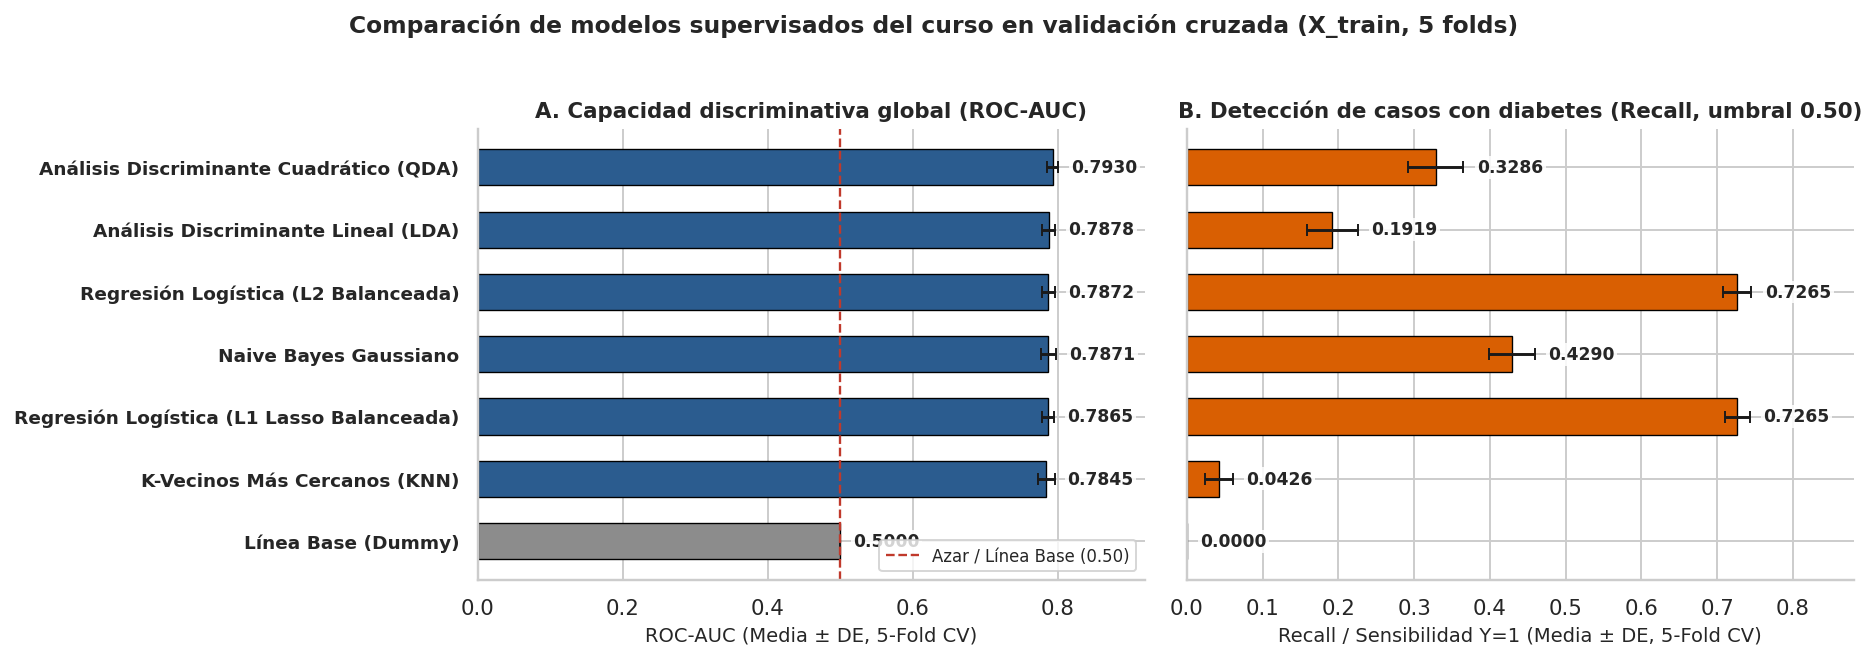

In [12]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import GridSearchCV, cross_validate
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis, QuadraticDiscriminantAnalysis
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier

modelos_busqueda = {
    '1. Línea Base (Dummy)': (
        DummyClassifier(strategy='most_frequent', random_state=42),
        {}
    ),
    '2. Regresión Logística (L2 Balanceada)': (
        LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42),
        {'modelo__C': [0.01, 0.1, 1.0, 10.0]}
    ),
    '3. Regresión Logística (L1 Lasso Balanceada)': (
        LogisticRegression(penalty='l1', solver='liblinear', class_weight='balanced', max_iter=1000, random_state=42),
        {'modelo__C': [0.05, 0.1, 0.5, 1.0, 5.0]}
    ),
    '4. Análisis Discriminante Lineal (LDA)': (
        LinearDiscriminantAnalysis(),
        {'modelo__solver': ['svd', 'lsqr']}
    ),
    '5. Análisis Discriminante Cuadrático (QDA)': (
        QuadraticDiscriminantAnalysis(),
        {'modelo__reg_param': [0.0, 0.1, 0.3, 0.5, 0.8]}
    ),
    '6. Naive Bayes Gaussiano': (
        GaussianNB(),
        {'modelo__var_smoothing': [1e-9, 1e-7, 1e-5, 1e-3, 1e-1]}
    ),
    '7. K-Vecinos Más Cercanos (KNN)': (
        KNeighborsClassifier(),
        {
            'modelo__n_neighbors': [5, 11, 21, 31, 41],
            'modelo__weights': ['uniform', 'distance'],
            'modelo__metric': ['euclidean', 'manhattan']
        }
    )
}

resultados_tabla = []
mejores_pipelines = {}

for nombre, (clf, param_grid) in modelos_busqueda.items():
    pipe = construir_pipeline(clf)
    if param_grid:
        grid = GridSearchCV(
            estimator=pipe,
            param_grid=param_grid,
            cv=cv,
            scoring='roc_auc',
            n_jobs=-1,
            refit=True
        )
        grid.fit(X_train, y_train)
        mejor_pipe = grid.best_estimator_
        mejores_params = {k.replace('modelo__', ''): v for k, v in grid.best_params_.items()}
    else:
        mejor_pipe = pipe.fit(X_train, y_train)
        mejores_params = 'N/A (mayoría)'

    mejores_pipelines[nombre] = mejor_pipe

    cv_res = cross_validate(mejor_pipe, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)

    resultados_tabla.append({
        'Modelo': nombre,
        'Hiperparámetros óptimos': str(mejores_params),
        'ROC-AUC (CV)': f"{cv_res['test_roc_auc'].mean():.4f} ± {cv_res['test_roc_auc'].std():.4f}",
        'Recall Y=1 (CV)': f"{cv_res['test_recall'].mean():.4f} ± {cv_res['test_recall'].std():.4f}",
        'Precision Y=1 (CV)': f"{cv_res['test_precision'].mean():.4f} ± {cv_res['test_precision'].std():.4f}",
        'F1-Score Y=1 (CV)': f"{cv_res['test_f1'].mean():.4f} ± {cv_res['test_f1'].std():.4f}",
        'Accuracy (CV)': f"{cv_res['test_accuracy'].mean():.4f} ± {cv_res['test_accuracy'].std():.4f}",
        '_auc_mean': cv_res['test_roc_auc'].mean()
    })

df_comparacion = pd.DataFrame(resultados_tabla).sort_values('_auc_mean', ascending=False).drop(columns=['_auc_mean'])
print(" TABLA COMPARATIVA DE MODELOS (5-FOLD STRATIFIED CV EN X_TRAIN) ")
print(df_comparacion.to_string(index=False))

df_plot_cv = pd.DataFrame(resultados_tabla).sort_values('_auc_mean', ascending=True)
nombres_cortos = [m.split('. ')[1] for m in df_plot_cv['Modelo']]
auc_means = [float(x.split(' ± ')[0]) for x in df_plot_cv['ROC-AUC (CV)']]
auc_stds = [float(x.split(' ± ')[1]) for x in df_plot_cv['ROC-AUC (CV)']]
rec_means = [float(x.split(' ± ')[0]) for x in df_plot_cv['Recall Y=1 (CV)']]
rec_stds = [float(x.split(' ± ')[1]) for x in df_plot_cv['Recall Y=1 (CV)']]

sns.set_theme(style='whitegrid', context='notebook')
fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.6), sharey=True)

y_pos = np.arange(len(nombres_cortos))
colores_auc = ['#8c8c8c' if 'Dummy' in n else '#2b5c8f' for n in nombres_cortos]
colores_rec = ['#8c8c8c' if 'Dummy' in n else '#d95f02' for n in nombres_cortos]

axes[0].barh(y_pos, auc_means, xerr=auc_stds, color=colores_auc, height=0.58, edgecolor='black', linewidth=0.7, capsize=3)
axes[0].axvline(0.50, color='#c0392b', linestyle='--', linewidth=1.2, zorder=2, label='Azar / Línea Base (0.50)')
axes[0].set_yticks(y_pos)
axes[0].set_yticklabels(nombres_cortos, fontsize=9.5, fontweight='bold')
axes[0].set_xlabel('ROC-AUC (Media ± DE, 5-Fold CV)', fontsize=10)
axes[0].set_title('A. Capacidad discriminativa global (ROC-AUC)', fontsize=11, fontweight='bold')
axes[0].set_xlim(0, 0.92)
for i, (m, s) in enumerate(zip(auc_means, auc_stds)):
    axes[0].text(
        m + s + 0.018, i, f'{m:.4f}', va='center', fontsize=8.8, fontweight='bold',
        bbox=dict(facecolor='white', alpha=0.85, edgecolor='none', pad=1.2), zorder=4
    )
axes[0].legend(loc='lower right', fontsize=8.5, frameon=True)
sns.despine(ax=axes[0], top=True, right=True)

axes[1].barh(y_pos, rec_means, xerr=rec_stds, color=colores_rec, height=0.58, edgecolor='black', linewidth=0.7, capsize=3)
axes[1].set_xlabel('Recall / Sensibilidad Y=1 (Media ± DE, 5-Fold CV)', fontsize=10)
axes[1].set_title('B. Detección de casos con diabetes (Recall, umbral 0.50)', fontsize=11, fontweight='bold')
axes[1].set_xlim(0, 0.88)
for i, (m, s) in enumerate(zip(rec_means, rec_stds)):
    axes[1].text(
        m + s + 0.018, i, f'{m:.4f}', va='center', fontsize=8.8, fontweight='bold',
        bbox=dict(facecolor='white', alpha=0.85, edgecolor='none', pad=1.2), zorder=4
    )
sns.despine(ax=axes[1], top=True, right=True)

fig.suptitle('Comparación de modelos supervisados del curso en validación cruzada (X_train, 5 folds)', fontsize=12, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('figura_e2_comparacion_modelos_cv.png', bbox_inches='tight', dpi=300)
plt.show()

# 4. Validación, métricas e interpretación preliminar

Umbral óptimo Youden (ajustado solo en Train CV) -> Logit L2: 0.425 (Youden=0.4568) | QDA: 0.12 (Youden=0.4459)

 EVALUACIÓN DEFINITIVA EN CONJUNTO DE PRUEBA (X_TEST, N = 1.695) 
                        Modelo / Configuración  Umbral  ROC-AUC  PR-AUC  Recall (Sens.)  Especificidad  Precision  F1-Score  Accuracy  VP  FN  FP   VN
                            Línea Base (Dummy)   0.500   0.5000  0.1664          0.0000         1.0000     0.0000    0.0000    0.8336   0 282   0 1413
      Regresión Logística L2 (C=0.1, balanced)   0.500   0.7869  0.3692          0.7163         0.7105     0.3306    0.4524    0.7115 202  80 409 1004
                           QDA (reg_param=0.1)   0.500   0.7950  0.3785          0.3333         0.9222     0.4608    0.3868    0.8242  94 188 110 1303
                              LDA (solver=svd)   0.500   0.7905  0.3981          0.2021         0.9554     0.4750    0.2836    0.8301  57 225  63 1350
     Naive Bayes Gaussiano (var_smoothing=0.1)   0.500   0.7944  0

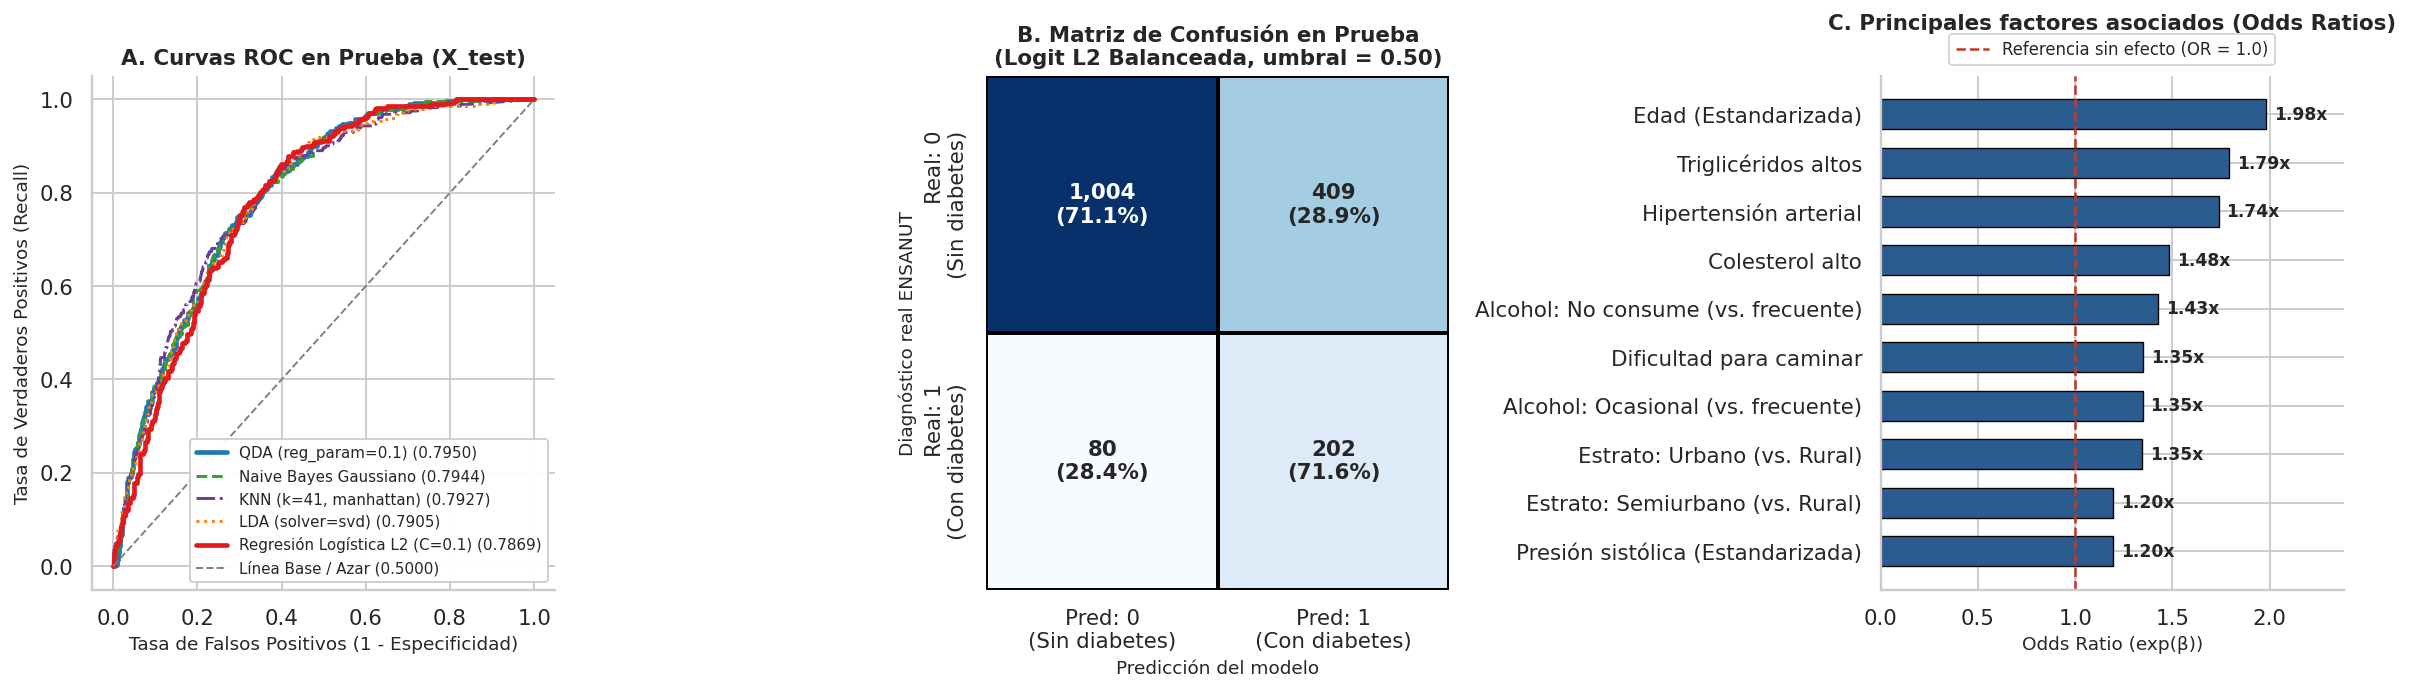

In [13]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import cross_val_predict
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis, QuadraticDiscriminantAnalysis
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    roc_auc_score, roc_curve, average_precision_score,
    confusion_matrix, accuracy_score, recall_score, precision_score, f1_score
)

modelos_finales = {
    'Línea Base (Dummy)': DummyClassifier(strategy='most_frequent', random_state=42),
    'Regresión Logística L2 (C=0.1, balanced)': LogisticRegression(C=0.1, class_weight='balanced', max_iter=1000, random_state=42),
    'QDA (reg_param=0.1)': QuadraticDiscriminantAnalysis(reg_param=0.1),
    'LDA (solver=svd)': LinearDiscriminantAnalysis(solver='svd'),
    'Naive Bayes Gaussiano (var_smoothing=0.1)': GaussianNB(var_smoothing=0.1),
    'KNN (k=41, manhattan, distance)': KNeighborsClassifier(n_neighbors=41, metric='manhattan', weights='distance')
}

def buscar_umbral_youden_train(pipe, X_tr, y_tr, cv_obj):
    probs_oof = cross_val_predict(pipe, X_tr, y_tr, cv=cv_obj, method='predict_proba', n_jobs=-1)[:, 1]
    umbrales = np.linspace(0.10, 0.80, 141)
    mejor_t, mejor_youden = 0.50, -1.0
    for t in umbrales:
        preds = (probs_oof >= t).astype(int)
        rec = recall_score(y_tr, preds)
        tn, fp, fn, tp = confusion_matrix(y_tr, preds).ravel()
        esp = tn / (tn + fp)
        youden = rec + esp - 1
        if youden > mejor_youden:
            mejor_youden = youden
            mejor_t = t
    return round(float(mejor_t), 3), round(float(mejor_youden), 4)

pipe_logit = construir_pipeline(modelos_finales['Regresión Logística L2 (C=0.1, balanced)'])
pipe_qda = construir_pipeline(modelos_finales['QDA (reg_param=0.1)'])

umbral_logit, youden_logit = buscar_umbral_youden_train(pipe_logit, X_train, y_train, cv)
umbral_qda, youden_qda = buscar_umbral_youden_train(pipe_qda, X_train, y_train, cv)

print(f"Umbral óptimo Youden (ajustado solo en Train CV) -> Logit L2: {umbral_logit} (Youden={youden_logit}) | QDA: {umbral_qda} (Youden={youden_qda})")

def evaluar_en_test(nombre, pipe, umbral=0.50):
    pipe.fit(X_train, y_train)
    probs = pipe.predict_proba(X_test)[:, 1]
    preds = (probs >= umbral).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, preds).ravel()
    esp = tn / (tn + fp)
    return {
        'Modelo / Configuración': nombre,
        'Umbral': umbral,
        'ROC-AUC': round(roc_auc_score(y_test, probs), 4),
        'PR-AUC': round(average_precision_score(y_test, probs), 4),
        'Recall (Sens.)': round(recall_score(y_test, preds, zero_division=0), 4),
        'Especificidad': round(esp, 4),
        'Precision': round(precision_score(y_test, preds, zero_division=0), 4),
        'F1-Score': round(f1_score(y_test, preds, zero_division=0), 4),
        'Accuracy': round(accuracy_score(y_test, preds), 4),
        'VP': tp, 'FN': fn, 'FP': fp, 'VN': tn
    }

filas_test = []
for nombre, clf in modelos_finales.items():
    filas_test.append(evaluar_en_test(nombre, construir_pipeline(clf), umbral=0.50))

filas_test.append(evaluar_en_test(f'Regresión Logística L2 (Umbral tamizaje={umbral_logit})', pipe_logit, umbral=umbral_logit))
filas_test.append(evaluar_en_test(f'QDA (reg_param=0.1, Umbral tamizaje={umbral_qda})', pipe_qda, umbral=umbral_qda))

df_test_res = pd.DataFrame(filas_test)
print("\n EVALUACIÓN DEFINITIVA EN CONJUNTO DE PRUEBA (X_TEST, N = 1.695) ")
print(df_test_res.to_string(index=False))

pipe_logit.fit(X_train, y_train)
preproc_fit = pipe_logit.named_steps['preprocesamiento']
nombres_limpios = [
    f.replace('num__', '').replace('cat__', '').replace('bin__', '')
    for f in preproc_fit.get_feature_names_out()
]
coefs = pipe_logit.named_steps['modelo'].coef_[0]
df_or = pd.DataFrame({
    'Variable': nombres_limpios,
    'Coeficiente (Beta)': np.round(coefs, 4),
    'Odds Ratio (exp Beta)': np.round(np.exp(coefs), 4)
}).sort_values('Odds Ratio (exp Beta)', ascending=False)

print("\nINTERPRETABILIDAD CLÍNICA: COEFICIENTES Y ODDS RATIOS (REGRESIÓN LOGÍSTICA L2) ")
print(df_or.to_string(index=False))

probs_test_logit = pipe_logit.predict_proba(X_test)[:, 1]
preds_test_logit = (probs_test_logit >= 0.50).astype(int)

df_errores = X_test.copy()
df_errores['Real'] = y_test.values
df_errores['Pred'] = preds_test_logit
df_errores['Prob_Diabetes'] = probs_test_logit

def clasificar_caso(row):
    if row['Real'] == 1 and row['Pred'] == 1:
        return 'VP (Detectado)'
    elif row['Real'] == 1 and row['Pred'] == 0:
        return 'FN (No detectado)'
    elif row['Real'] == 0 and row['Pred'] == 1:
        return 'FP (Falsa alarma)'
    else:
        return 'VN (Sano correcto)'

df_errores['Tipo_Resultado'] = df_errores.apply(clasificar_caso, axis=1)

print("\n ANÁLISIS DE PERFIL DE ERRORES EN X_TEST (REGRESIÓN LOGÍSTICA L2, UMBRAL 0.50) ")
resumen_errores = df_errores.groupby('Tipo_Resultado').agg(
    N=('Real', 'count'),
    Prob_Media=('Prob_Diabetes', 'mean'),
    Edad_Media=('EDAD', 'mean'),
    IMC_Medio=('IMC', 'mean'),
    PAS_Media=('PAS_MEDIA', 'mean'),
    Pct_Hipertension=('HIPERTENSION', lambda s: s.mean()*100),
    Pct_Colesterol=('COLESTEROL_ALTO', lambda s: s.mean()*100),
    Pct_Dif_Caminar=('DIF_CAMINAR', lambda s: s.mean()*100)
).round(2)
print(resumen_errores.to_string())

sns.set_theme(style='whitegrid', context='notebook')
fig, axes = plt.subplots(1, 3, figsize=(17.0, 5.1))

modelos_roc = [
    ('QDA (reg_param=0.1)', QuadraticDiscriminantAnalysis(reg_param=0.1), '#1f78b4', '-'),
    ('Naive Bayes Gaussiano', GaussianNB(var_smoothing=0.1), '#33a02c', '--'),
    ('KNN (k=41, manhattan)', KNeighborsClassifier(n_neighbors=41, metric='manhattan', weights='distance'), '#6a3d9a', '-.'),
    ('LDA (solver=svd)', LinearDiscriminantAnalysis(solver='svd'), '#ff7f00', ':'),
    ('Regresión Logística L2 (C=0.1)', LogisticRegression(C=0.1, class_weight='balanced', max_iter=1000, random_state=42), '#e31a1c', '-')
]

for nombre, clf, color, estilo in modelos_roc:
    pipe = construir_pipeline(clf).fit(X_train, y_train)
    probs = pipe.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, probs)
    auc_val = roc_auc_score(y_test, probs)
    lw = 2.4 if 'Logística' in nombre or 'QDA' in nombre else 1.5
    axes[0].plot(fpr, tpr, label=f'{nombre} ({auc_val:.4f})', color=color, linestyle=estilo, linewidth=lw)

axes[0].plot([0, 1], [0, 1], color='gray', linestyle='--', linewidth=1, label='Línea Base / Azar (0.5000)')
axes[0].set_xlabel('Tasa de Falsos Positivos (1 - Especificidad)', fontsize=9.5)
axes[0].set_ylabel('Tasa de Verdaderos Positivos (Recall)', fontsize=9.5)
axes[0].set_title('A. Curvas ROC en Prueba (X_test)', fontsize=11, fontweight='bold')
axes[0].legend(loc='lower right', fontsize=7.8, frameon=True, framealpha=0.95)
sns.despine(ax=axes[0], top=True, right=True)

cm = confusion_matrix(y_test, preds_test_logit)
cm_pct = cm / cm.sum(axis=1, keepdims=True) * 100
annot_matrix = np.empty(cm.shape, dtype=object)
for i in range(2):
    for j in range(2):
        annot_matrix[i, j] = f"{cm[i, j]:,}\n({cm_pct[i, j]:.1f}%)"

sns.heatmap(
    cm, annot=annot_matrix, fmt='', cmap='Blues', cbar=False,
    xticklabels=['Pred: 0\n(Sin diabetes)', 'Pred: 1\n(Con diabetes)'],
    yticklabels=['Real: 0\n(Sin diabetes)', 'Real: 1\n(Con diabetes)'],
    annot_kws={'size': 11, 'weight': 'bold'}, linewidths=1.2, linecolor='black', ax=axes[1]
)
axes[1].set_title('B. Matriz de Confusión en Prueba\n(Logit L2 Balanceada, umbral = 0.50)', fontsize=11, fontweight='bold')
axes[1].set_xlabel('Predicción del modelo', fontsize=9.5)
axes[1].set_ylabel('Diagnóstico real ENSANUT', fontsize=9.5)

top_or = df_or.head(10).sort_values('Odds Ratio (exp Beta)', ascending=True)
etiquetas_or = {
    'EDAD': 'Edad (Estandarizada)',
    'TRIGLICERIDOS_ALTOS': 'Triglicéridos altos',
    'HIPERTENSION': 'Hipertensión arterial',
    'COLESTEROL_ALTO': 'Colesterol alto',
    'CONSUMO_ALCOHOL_No_consume': 'Alcohol: No consume (vs. frecuente)',
    'DIF_CAMINAR': 'Dificultad para caminar',
    'CONSUMO_ALCOHOL_Ocasional': 'Alcohol: Ocasional (vs. frecuente)',
    'ESTRATO_URBANO_Urbano': 'Estrato: Urbano (vs. Rural)',
    'ESTRATO_URBANO_Semiurbano': 'Estrato: Semiurbano (vs. Rural)',
    'PAS_MEDIA': 'Presión sistólica (Estandarizada)'
}
y_labels_or = [etiquetas_or.get(v, v) for v in top_or['Variable']]

axes[2].barh(y_labels_or, top_or['Odds Ratio (exp Beta)'], color='#2b5c8f', height=0.62, edgecolor='black', linewidth=0.7)
axes[2].axvline(1.0, color='#c0392b', linestyle='--', linewidth=1.3, label='Referencia sin efecto (OR = 1.0)')
axes[2].set_xlabel('Odds Ratio (exp(β))', fontsize=9.5)
axes[2].set_title('C. Principales factores asociados (Odds Ratios)', fontsize=11, fontweight='bold', pad=24)
axes[2].set_xlim(0, 2.38)
for i, v in enumerate(top_or['Odds Ratio (exp Beta)']):
    axes[2].text(v + 0.04, i, f'{v:.2f}x', va='center', fontsize=8.8, fontweight='bold')
axes[2].legend(loc='lower center', bbox_to_anchor=(0.5, 1.005), frameon=True, fontsize=8.5)
sns.despine(ax=axes[2], top=True, right=True)

plt.tight_layout()
plt.savefig('figura_e2_evaluacion_test.png', bbox_inches='tight', dpi=300)
plt.show()